# Qwen3-VL-4B-Instruct 하자 짧은 설명 생성 — 인터랙티브 검증

**스파이크/검증용 코드입니다. 프로덕션 코드가 아닙니다.**

CH009 계획(`.claude/plans/ai/CH009-quality-defect-vlm.md`) "1. 후보 선정" ~ "2. 검증 축"에
대응한다. `verify_qwen3vl.py`로 1차 스모크 테스트(가동 여부)는 이미 통과했다 — 이 노트북은
그 다음 단계, 즉 **셀 단위로 결과를 보면서 크롭 크기·프롬프트 문구를 바로 바꿔볼 수 있게**
만든 버전이다.

### 이전 스모크 테스트에서 확인된 것

- `Qwen/Qwen3-VL-4B-Instruct`가 `qual` conda 환경(RTX 4070 Laptop, VRAM 8GB)에서 **4bit
  양자화(bitsandbytes nf4)**로 정상 로드된다 — VRAM 사용 약 2.7GB(peak 2.87GB), SAM3
  (fp16 ~1.7GB)와 합쳐도 8GB 예산에 여유가 있다.
- 한국어 프롬프트에 **번역 단계 없이 직접 한국어 문장**을 생성한다.
- 다만 SAM3 실제 bbox(14~46px 폭의 아주 작은 크롭)로 테스트하니 출력이 **입력 라벨을 그대로
  재진술하는 수준**(예: "얼룩이 있는 부분이 확대되어 보입니다")에 그쳤다 — 색상·모양·범위 같은
  구체적 시각 정보가 거의 없었다.

### 이 노트북이 확인하려는 것

1. 크롭을 더 크게(§3 `MIN_CROP_SIZE`) 하면 출력이 더 구체적으로 나아지는가
2. 프롬프트에서 라벨을 미리 알려주는 것과, 안 알려주고 순수하게 보이는 것만 묻는 것의 차이
   (§3 `PROMPT_VARIANTS`)
3. 이미지·finding을 바꿔가며(§5) 같은 경향이 재현되는가

### 2026-07-31 업데이트 — 위치 hallucination 발견 + 수정

크롭 크기를 키운 뒤로 색상·모양 묘사는 좋아졌는데, 대신 **"청바지의 허리 부분" 같은 위치
설명이 반복적으로 등장**했다. 크롭 이미지만으로는 옷 전체에서 어디인지 알 방법이 없는데도
모델이 그럴듯하게 지어낸 것 — 전형적인 hallucination이다.

그래서 **위치는 VLM에게 묻지 않는다.** 대신 SAM3가 이미 확정한 bbox 좌표로 기하학적
위치(`loaders.bbox_grid_position()`, 3x3 격자)를 계산하고, VLM 출력(시각적 특징만)과
`loaders.compose_finding_bullet()`로 합쳐서 최종 한 줄을 만든다(§4·§5에 반영). `PROMPT_VARIANTS`
세 개도 전부 "위치는 언급하지 마세요"를 명시하도록 통일했다.

### 실행 순서

셀을 위에서 아래로 한 번 실행한 뒤, §5(단일 finding 재실험) 셀만 값을 바꿔가며 반복 실행하면
된다 — 모델은 §2에서 한 번만 로드하고 계속 재사용한다.

## 0. 의존성 설치

`requirements-vlm.txt`를 설치한다. `qual` conda 환경(SAM3 스파이크와 공유, transformers>=5.0)에
`bitsandbytes`만 추가로 설치하면 된다.

In [ ]:
# %pip install -q -r requirements-vlm.txt

Note: you may need to restart the kernel to use updated packages.


## 0-1. CUDA / GPU 확인

4bit 양자화도 GPU 전제라 CUDA가 없으면 이 스파이크는 사실상 못 돈다.

In [18]:
import torch

print(f"torch          : {torch.__version__}")
print(f"cuda available : {torch.cuda.is_available()}")

if torch.cuda.is_available():
    _props = torch.cuda.get_device_properties(0)
    print(f"gpu            : {_props.name}")
    print(f"total VRAM     : {_props.total_memory / 1024**3:.2f} GB")
    print(f"cuda runtime   : {torch.version.cuda}")
else:
    print("[주의] CUDA를 찾지 못했습니다. 4bit 양자화도 GPU 전제라 CPU로는 사실상 못 돕니다.")

torch          : 2.13.0+cu130
cuda available : True
gpu            : NVIDIA GeForce RTX 4070 Laptop GPU
total VRAM     : 8.00 GB
cuda runtime   : 13.0


## 0-2. 설정 상수

`model_selection/model_registry.py` 관례대로 **바꿔 끼울 값을 한곳에 모은다.** 크롭
크기·프롬프트 문구·대상 이미지는 전부 여기(또는 §5 재실험 셀)에서만 고치면 된다.

In [19]:
import sys
from pathlib import Path

sys.path.insert(0, "..")  # qc_shared.py(QUAL/), sam3-condition-check 산출물 재사용
from qc_shared import IMAGE_EXTS, pad_bbox_clamped, use_korean_font  # noqa: E402

from loaders import (  # noqa: E402
    bbox_grid_position,
    build_defect_prompt,
    compose_finding_bullet,
    generate_from_image,
    load_qwen_vl,
)
from model_registry import ACTIVE_QUANTIZATION, ACTIVE_VLM, VLM_MODELS  # noqa: E402

MODEL_ID = VLM_MODELS[ACTIVE_VLM]

# --- 실험 대상 이미지/크롭 --- 여기 값만 바꾸면 다른 이미지·다른 크롭 설정으로 재실행된다.
# sam3-condition-check/outputs/qc_summary.json에 있는 이미지 중 하자가 있는 것들:
# denim(3), levis_patch(16), scratch(7), small_pro(6), black_washed(2), logo_test(1)
IMAGE_STEM = "scratch"  # sample_images/<stem>.* + outputs/<stem>_qc.json
CROP_PAD_RATIO = 0.6  # bbox 대비 여백 비율(sam3_qc_test.ipynb §8과 같은 상수)
MIN_CROP_SIZE = 160  # 1차 스모크 테스트(14~46px 크롭)가 정보 부족으로 보여 최소 크기를 보장

# --- 프롬프트 실험 --- 키만 바꾸면 다른 프롬프트로 스왑된다(model_selection 관례와 동일).
# 2026-07-31: 세 변형 모두 "위치는 언급하지 마세요"로 통일했다 — 크롭만 보고 위치를
# 추측하게 하면 "청바지의 허리 부분" 같은 hallucination이 생긴다는 게 실측으로 확인됐다.
# 위치는 VLM이 아니라 bbox_grid_position()이 기하학적으로 계산한다(아래 §4/§5).
# CH019: loaders.build_defect_prompt()에 few-shot 예시 2개(프로덕션
# worker/models/quality_vlm/prompts.py와 동일 문구)를 반영했다 — 그래서 "default"는 이제
# few-shot 포함 버전이다. "no_fewshot_baseline"은 few-shot 도입 전 문구를 그대로 남겨
# 둔 것으로, §4-1 비교 셀에서 "default"와 나란히 돌려 전/후 차이를 본다.
PROMPT_VARIANTS = {
    "default": None,  # None이면 loaders.build_defect_prompt() 그대로 사용(few-shot 포함, 라벨을 미리 알려줌)
    "no_fewshot_baseline": (
        "이 이미지는 중고 의류의 '{label}' 하자 부분을 확대한 사진입니다. "
        "옷의 어느 부위인지는 추측하거나 언급하지 마세요. "
        "색상, 모양, 크기, 질감 등 사진에서 실제로 보이는 시각적 특징만 한국어 한 문장으로 "
        "설명해 주세요. 보이지 않는 내용은 지어내지 마세요."
    ),
    "no_label_hint": (
        "이 이미지는 중고 의류의 한 부분을 확대한 사진입니다. "
        "옷의 어느 부위인지는 추측하거나 언급하지 마세요. "
        "표면에 보이는 상태(색, 모양, 얼룩/손상 여부 등)를 본 대로 한국어 한 문장으로 "
        "설명해 주세요. 보이지 않는 내용은 지어내지 마세요."
    ),
    "visual_detail": (
        "이 이미지는 중고 의류의 '{label}' 하자 부분을 확대한 사진입니다. "
        "옷의 어느 부위인지는 추측하거나 언급하지 마세요. "
        "색상, 모양, 크기, 질감 중 실제로 보이는 것만 한국어 한 문장으로 구체적으로 "
        "설명해 주세요. 보이지 않는 내용은 지어내지 마세요."
    ),
}
ACTIVE_PROMPT_VARIANT = "default"


def expand_bbox_to_min_size(bbox, pad_ratio, min_size, image_size):
    """pad_bbox_clamped로 여백을 준 뒤, 결과가 min_size보다 작으면 중심 기준으로 더 넓힌다."""
    x1, y1, x2, y2 = pad_bbox_clamped(bbox, pad_ratio, image_size)
    img_w, img_h = image_size
    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
    half_w = max((x2 - x1) / 2, min_size / 2)
    half_h = max((y2 - y1) / 2, min_size / 2)
    return [
        max(0, int(cx - half_w)),
        max(0, int(cy - half_h)),
        min(img_w, int(cx + half_w)),
        min(img_h, int(cy + half_h)),
    ]


def build_prompt(label, variant_key=None):
    variant = PROMPT_VARIANTS[variant_key or ACTIVE_PROMPT_VARIANT]
    if variant is None:
        return build_defect_prompt(label)
    return variant.format(label=label) if "{label}" in variant else variant


use_korean_font()
print(f"model_id={MODEL_ID}  quantization={ACTIVE_QUANTIZATION}")
print(f"prompt_variant={ACTIVE_PROMPT_VARIANT}")
print(f"crop: pad_ratio={CROP_PAD_RATIO}  min_size={MIN_CROP_SIZE}px")

model_id=Qwen/Qwen3-VL-4B-Instruct  quantization=4bit
prompt_variant=default
crop: pad_ratio=0.6  min_size=160px


## 1. 모델 로드 (VRAM 실측)

한 번만 실행한다 — 이후 셀들은 이미 로드된 `bundle`을 재사용한다.

In [20]:
import time


def _vram_report(tag):
    """(allocated_MB, peak_MB)를 찍고 반환. sam3_qc_test.ipynb의 관례와 동일."""
    if not torch.cuda.is_available():
        print(f"{tag:<20} (CPU 모드 - VRAM 측정 없음)")
        return (0.0, 0.0)
    alloc = torch.cuda.memory_allocated() / 1024**2
    peak = torch.cuda.max_memory_allocated() / 1024**2
    print(f"{tag:<20} allocated={alloc:9.1f} MB ({alloc / 1024:.2f} GB)   peak={peak:9.1f} MB")
    return (alloc, peak)


if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()
_vram_report("로드 전")

_t0 = time.time()
bundle = load_qwen_vl(MODEL_ID, quantization=ACTIVE_QUANTIZATION)
print(f"로드 소요: {time.time() - _t0:.1f}s")
_vram_report("로드 후")

로드 전                 allocated=   2784.2 MB (2.72 GB)   peak=   2784.2 MB


Loading weights: 100%|██████████| 713/713 [00:03<00:00, 205.75it/s]


로드 소요: 11.5s
로드 후                 allocated=   4813.5 MB (4.70 GB)   peak=   5585.8 MB


(4813.47412109375, 5585.81005859375)

## 2. 데이터 로드 — 이미지 + SAM3 findings

`IMAGE_STEM`이 가리키는 이미지와, 같은 이름의 SAM3 산출물(`<stem>_qc.json`)을 불러온다.

In [21]:
import json

from PIL import Image

SAMPLE_DIR = Path("../sam3-condition-check/sample_images")
OUTPUT_DIR = Path("../sam3-condition-check/outputs/masking")


def find_image_path(stem):
    for ext in IMAGE_EXTS:
        p = SAMPLE_DIR / f"{stem}{ext}"
        if p.is_file():
            return p
    raise FileNotFoundError(f"{stem} 이미지를 {SAMPLE_DIR}에서 못 찾았습니다")


# --- 실험 대상 이미지/크롭 --- 여기 값만 바꾸면 다른 이미지·다른 크롭 설정으로 재실행된다.
# sam3-condition-check/outputs/qc_summary.json에 있는 이미지 중 하자가 있는 것들:
# denim(3), levis_patch(16), scratch(7), small_pro(6), black_washed(2), logo_test(1)
IMAGE_STEM = "small_pro"  # sample_images/<stem>.* + outputs/<stem>_qc.json
CROP_PAD_RATIO = 0.6  # bbox 대비 여백 비율(sam3_qc_test.ipynb §8과 같은 상수)
MIN_CROP_SIZE = 160  # 1차 스모크 테스트(14~46px 크롭)가 정보 부족으로 보여 최소 크기를 보장


image_path = find_image_path(IMAGE_STEM)
findings_path = OUTPUT_DIR / f"{IMAGE_STEM}_qc.json"
findings = json.loads(findings_path.read_text(encoding="utf-8"))
image = Image.open(image_path).convert("RGB")

print(
    f"이미지: {image_path.name}  size={image.size}  "
    f"verdict={findings['verdict']}  findings={len(findings['instances'])}"
)
for inst in findings["instances"]:
    print(f"  [{inst['no']}] {inst['label']:<6} conf={inst['confidence']:.2f}  bbox={inst['bbox']}")

이미지: small_pro.jpg  size=(620, 620)  verdict=REVIEW  findings=6
  [1] 오염     conf=0.73  bbox=[339, 288, 403, 346]
  [2] 오염     conf=0.42  bbox=[457, 393, 490, 410]
  [3] 오염     conf=0.40  bbox=[486, 98, 522, 131]
  [4] 오염     conf=0.34  bbox=[504, 118, 523, 130]
  [5] 얼룩     conf=0.33  bbox=[413, 344, 511, 403]
  [6] 오염     conf=0.31  bbox=[486, 98, 504, 112]


## 3. 크롭 미리보기

모델에게 실제로 넘어갈 크롭 이미지를 먼저 눈으로 확인한다 — 텍스트 결과만 보고 판단하면
"크롭이 원래 이 정도로 작았는지"를 놓치기 쉽다.

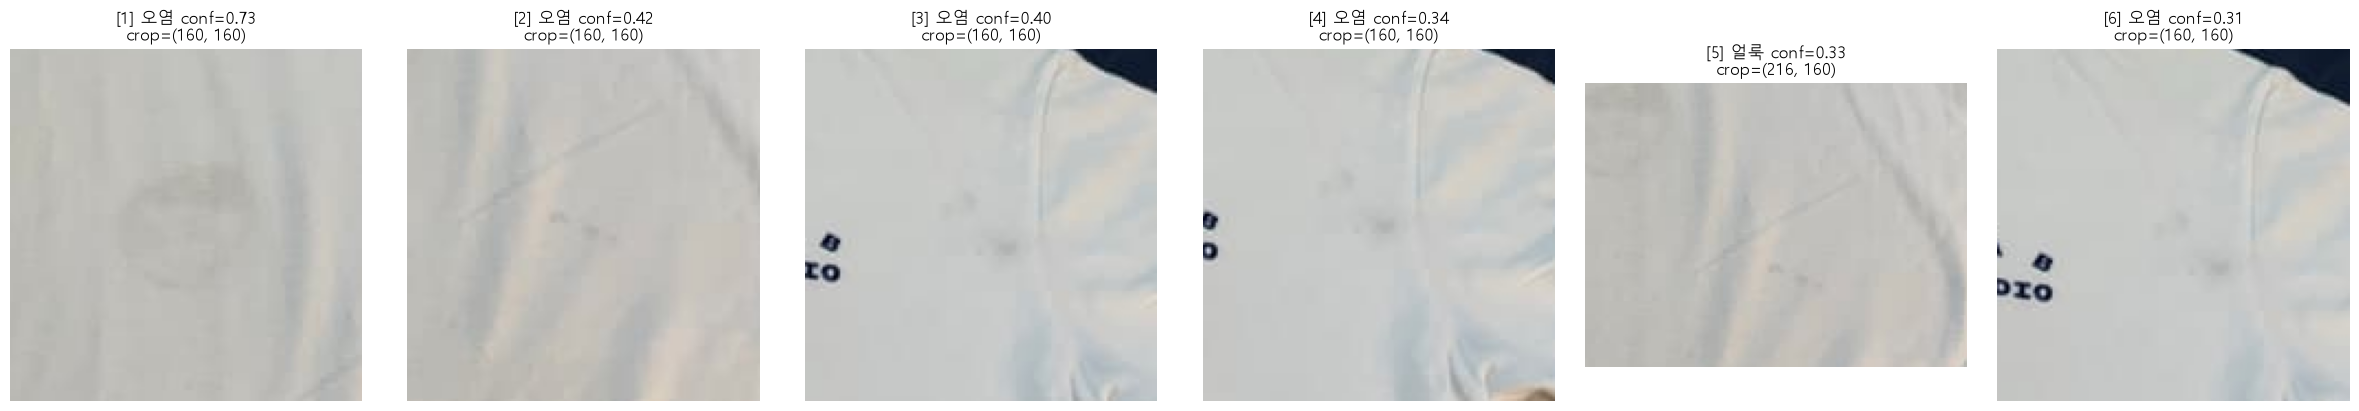

In [22]:
import matplotlib.pyplot as plt

crops = []
for inst in findings["instances"]:
    bbox = expand_bbox_to_min_size(inst["bbox"], CROP_PAD_RATIO, MIN_CROP_SIZE, image.size)
    crop = image.crop(bbox)
    crops.append((inst, bbox, crop))

fig, axes = plt.subplots(1, len(crops), figsize=(4 * len(crops), 4))
axes = [axes] if len(crops) == 1 else axes
for ax, (inst, bbox, crop) in zip(axes, crops):
    ax.imshow(crop)
    ax.set_title(f"[{inst['no']}] {inst['label']} conf={inst['confidence']:.2f}\ncrop={crop.size}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. 전체 findings VLM 추론

`IMAGE_STEM`의 모든 finding에 대해 크롭 + 설명을 나란히 본다.

C:\Users\SSAFY\AppData\Local\Temp\ipykernel_54724\1084923010.py:28: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout()


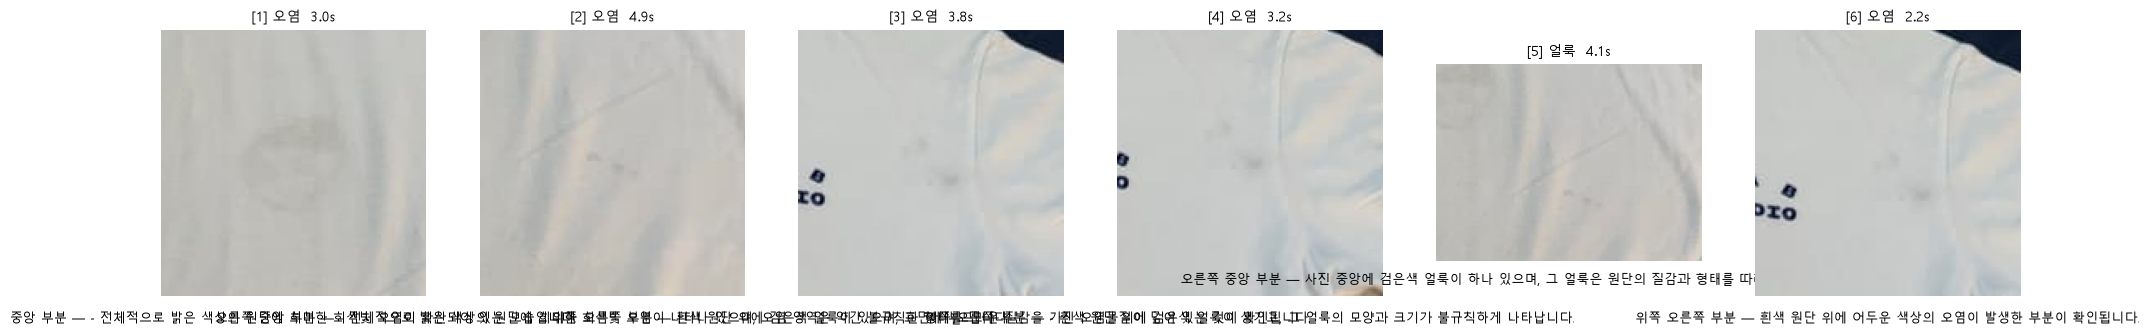

[1] 오염 -> 중앙 부분 — - 전체적으로 밝은 색상의 원단에 희미한 회색빛 오염이 확산되어 있는 모습입니다.
[2] 오염 -> 오른쪽 중앙 부분 — - 전체적으로 밝은 색상의 원단에 희미한 회색빛 오염이 나타나 있으며, 오염 영역은 약간 불규칙한 형태를 띱니다.
[3] 오염 -> 위쪽 오른쪽 부분 — 흰색 원단 위에 검은색 얼룩이 있으며, 표면에 부드러운 질감을 가진 오염물질이 덮여 있는 것이 확인됩니다.
[4] 오염 -> 위쪽 오른쪽 부분 — - 흰색 원단 위에 검은색 얼룩이 생기고, 그 얼룩의 모양과 크기가 불규칙하게 나타납니다.
[5] 얼룩 -> 오른쪽 중앙 부분 — 사진 중앙에 검은색 얼룩이 하나 있으며, 그 얼룩은 원단의 질감과 형태를 따라 부드럽게 흐르는 모양을 띱니다.
[6] 오염 -> 위쪽 오른쪽 부분 — 흰색 원단 위에 어두운 색상의 오염이 발생한 부분이 확인됩니다.


In [23]:
results = []
for inst, bbox, crop in crops:
    prompt_text = build_prompt(inst["label"])
    _t0 = time.time()
    description = generate_from_image(bundle, crop, prompt_text)
    gen_s = time.time() - _t0
    # 위치는 VLM 출력이 아니라 원본 bbox(크롭 bbox 아님)로 기하학적으로 계산한다.
    position = bbox_grid_position(inst["bbox"], image.size)
    bullet = compose_finding_bullet(position, description)
    results.append(
        {
            "no": inst["no"],
            "label": inst["label"],
            "bbox": bbox,
            "gen_s": gen_s,
            "description": description,
            "bullet": bullet,
        }
    )

fig, axes = plt.subplots(1, len(crops), figsize=(4 * len(crops), 5.5))
axes = [axes] if len(crops) == 1 else axes
for ax, (inst, bbox, crop), r in zip(axes, crops, results):
    ax.imshow(crop)
    ax.set_title(f"[{r['no']}] {r['label']}  {r['gen_s']:.1f}s", fontsize=10)
    ax.axis("off")
    ax.text(0.5, -0.06, r["bullet"], transform=ax.transAxes, ha="center", va="top", fontsize=9, wrap=True)
plt.tight_layout()
plt.show()

for r in results:
    print(f"[{r['no']}] {r['label']} -> {r['bullet']}")

## 4-1. Few-shot 전/후 비교 (CH019)

`no_fewshot_baseline`(few-shot 도입 전 문구)과 `default`(few-shot 포함, 프로덕션
`worker/models/quality_vlm/prompts.py`와 동일)를 **같은 크롭·같은 finding**으로 나란히
생성해서 문체·구체성·생성 시간 차이를 비교한다. §4는 `ACTIVE_PROMPT_VARIANT` 하나만 쓰지만,
여기는 두 변형을 한 번에 다 돌려서 바로 옆에서 비교할 수 있게 한다.

In [24]:
_COMPARE_VARIANTS = ("no_fewshot_baseline", "default")

compare_rows = []
for inst, bbox, crop in crops:
    for variant_key in _COMPARE_VARIANTS:
        prompt_text = build_prompt(inst["label"], variant_key=variant_key)
        _t0 = time.time()
        description = generate_from_image(bundle, crop, prompt_text)
        gen_s = time.time() - _t0
        compare_rows.append(
            {
                "no": inst["no"],
                "label": inst["label"],
                "variant": variant_key,
                "gen_s": round(gen_s, 2),
                "description": description,
            }
        )

for row in compare_rows:
    print(
        f"[{row['no']}] {row['label']:<6} {row['variant']:<20} "
        f"{row['gen_s']:>5.2f}s  {row['description']}"
    )

[1] 오염     no_fewshot_baseline   4.60s  밝은 색상의 옷재료 위에 희미한 회색 빛이 반사되는 작은 원형 오염이 있으며, 표면은 부드럽고 매끄러운 질감을 보입니다.
[1] 오염     default               2.47s  - 전체적으로 흰색을 기준으로 어두운 흔적이 있는 오염이 확인됩니다.
[2] 오염     no_fewshot_baseline   4.63s  밝은 색상의 옷 위에 희미한 회색 선과 작은 점이 흩어져 있는 모습이며, 표면은 부드럽고 약간의 주름이 있는 질감을 보입니다.
[2] 오염     default               2.94s  - 전체적으로 밝은 색상의 원단에 희미한 회색빛 오염이 확산되어 있는 것이 확인됩니다.
[3] 오염     no_fewshot_baseline   3.89s  흰색 소재의 옷에 검은색으로 인쇄된 글자들이 일부 보이며, 그 옆에는 작은 크기의 흐릿한 얼룩이 하나 존재합니다.
[3] 오염     default               4.04s  흰색 원단 위에 어두운 색상의 오염이 형성되어 있으며, 그 오염은 부드럽게 퍼진 형태를 보입니다.
[4] 오염     no_fewshot_baseline   4.31s  흰색 소재의 옷에 검은색 점이 두 개 있으며, 그 옷의 표면에는 약간의 반짝임이 있는 흰색 얼룩이 하나 보입니다.
[4] 오염     default               4.09s  흰색 원단 위에 어두운 색상의 오염이 나타나 있으며, 그 오염부분은 부드럽게 퍼진 형태를 보입니다.
[5] 얼룩     no_fewshot_baseline   6.09s  밝은 색상의 옷재질에 희미한 회색 얼룩이 하나 있으며, 그 얼룩은 길고 얇은 선형의 형태를 띠고 있고, 표면에는 약간의 주름과 질감이 감지됩니다.
[5] 얼룩     default               3.82s  얼룩은 회색빛이 도는 어두운 색상의 작은 пят자 형태로, 표면에 불규칙한 모양과 질감을 가진

## TO-DO: 프롬프트 실험 백로그

CH011 계획(`.claude/plans/ai/CH011-quality-vlm-production-wiring.md`)이 프로덕션
연결까지 끝냈다. 아래는 프롬프트 개선 실험 목록이다 — **여기서 먼저 검증한 뒤에만**
`worker/models/quality_vlm/prompts.py`의 `build_defect_prompt()`에 반영한다.

- [ ] 프롬프트 엔지니어링 — 문구 변형을 계속 실험(§0-2 `PROMPT_VARIANTS` 확장)
- [ ] One-shot 프롬프팅 — 텍스트 예시 1개로 답변 형식(문장 길이·순서)을 고정
- [x] Few-shot 프롬프팅 — 예시 2개, 이미지 없이 텍스트만으로 형식 고정(CH019).
      `loaders.build_defect_prompt()`와 프로덕션 `worker/models/quality_vlm/prompts.py`
      양쪽에 반영 완료. §4-1에서 few-shot 도입 전(`no_fewshot_baseline`)과 비교 가능.
- [ ] §4-1 비교 결과를 실제 GPU에서 실행해 few-shot이 문체·구체성을 실제로 개선하는지
      확인(사용자가 `qual` conda 환경에서 직접 실행 — CH019 계획의 미결정 사항 1번)
- [ ] 위 실험에서 좋은 결과가 나오면 `worker/models/quality_vlm/prompts.py`의
      `build_defect_prompt()`에 반영하고, 이 체크리스트도 갱신
- [x] 전체 이미지 + 넘버링 일괄 생성 비교는 결론이 나서(배치 방식 채택) 이 노트북 에서는 제거했다. 이어지는 실측은 `batch_pipeline_check.ipynb`(SAM3 실시간 탐지 + bbox 미표시 배치 설명 + 최종 JSON 조립까지 end-to-end)에서 다룬다.

## 5. 단일 finding 재실험 — 즉시 바꿔가며 반복 실행

`FOCUS_*` 값만 바꾸고 이 셀만 다시 실행하면 된다. 모델은 §1에서 이미 로드된 `bundle`을
그대로 쓰므로 재실행마다 몇 초(생성 시간)만 걸린다. `FOCUS_PROMPT_VARIANT`는 §0-2
`PROMPT_VARIANTS`의 키 중 하나를 쓴다.

gen=4.36s  variant=visual_detail  crop=(320, 320)  bbox=[211, 157, 531, 477]
prompt : 이 이미지는 중고 의류의 '오염' 하자 부분을 확대한 사진입니다. 옷의 어느 부위인지는 추측하거나 언급하지 마세요. 색상, 모양, 크기, 질감 중 실제로 보이는 것만 한국어 한 문장으로 구체적으로 설명해 주세요. 보이지 않는 내용은 지어내지 마세요.
설명   : 흰색의 직물 위에 약간 어두운 톤의 원형 얼룩이 있으며, 표면에 흔들리는 주름과 함께 부드러운 질감을 보입니다.
최종   : 중앙 부분 — 흰색의 직물 위에 약간 어두운 톤의 원형 얼룩이 있으며, 표면에 흔들리는 주름과 함께 부드러운 질감을 보입니다.


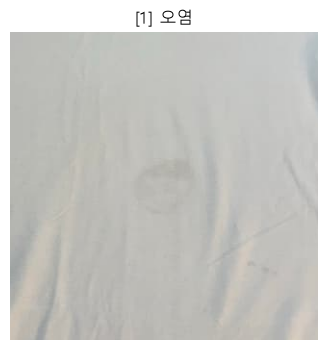

In [25]:
# 여기 값만 바꿔서 셀을 재실행한다.
FOCUS_NO = 1  # findings 중 확인할 번호(no)
FOCUS_PAD_RATIO = CROP_PAD_RATIO
FOCUS_MIN_SIZE = 320  # 예: 스모크 테스트보다 훨씬 큰 크롭으로 재시도
FOCUS_PROMPT_VARIANT = "visual_detail"

_inst = next(i for i in findings["instances"] if i["no"] == FOCUS_NO)
_bbox = expand_bbox_to_min_size(_inst["bbox"], FOCUS_PAD_RATIO, FOCUS_MIN_SIZE, image.size)
_crop = image.crop(_bbox)

_variant = PROMPT_VARIANTS[FOCUS_PROMPT_VARIANT]
if _variant is None:
    _prompt = build_defect_prompt(_inst["label"])
elif "{label}" in _variant:
    _prompt = _variant.format(label=_inst["label"])
else:
    _prompt = _variant

_t0 = time.time()
_description = generate_from_image(bundle, _crop, _prompt)
_position = bbox_grid_position(_inst["bbox"], image.size)
_bullet = compose_finding_bullet(_position, _description)
print(f"gen={time.time() - _t0:.2f}s  variant={FOCUS_PROMPT_VARIANT}  crop={_crop.size}  bbox={_bbox}")
print(f"prompt : {_prompt}")
print(f"설명   : {_description}")
print(f"최종   : {_bullet}")

plt.figure(figsize=(4, 4))
plt.imshow(_crop)
plt.axis("off")
plt.title(f"[{FOCUS_NO}] {_inst['label']}")
plt.show()

## 6. VRAM 최종 리포트

In [26]:
_vram_report("최종")

최종                   allocated=   4813.5 MB (4.70 GB)   peak=   5585.8 MB


(4813.474609375, 5585.81005859375)